# Percobaan Model #2: DINOv2 ViT-S/14 (Final)
Kenap model ke-2 ini harus **DINOv2 ViT-S/14?** karena DINOv2 dilatih pada gambar dalam jumlah sangat besar tanpa label, sehingga fitur visualnya sudah kuat. Varian ViT-S/14 berukuran kecil (small) dimana dia menggunakan 21 juta parameter pada backbone, jadi masih muat di GPU laptop yang saya gunakan.

**Istilah dasar yang dipakai di notebook ini**
- **Pretrained model**: model yang sudah belajar dari data besar sebelumnya. Kita tidak mulai dari bobot acak.
- **Backbone dan head**: backbone mengubah gambar menjadi vektor fitur, lalu head (satu layer `Linear`) mengubah vektor itu menjadi 5 skor (logit), satu per kelas.
- **Frozen backbone**: bobot backbone dikunci, hanya head yang dilatih.
- **Partial fine-tuning**: beberapa blok Transformer terakhir ikut dilatih supaya fiturnya menyesuaikan dengan data sampah.
- **Macro-F1**: rata-rata F1 semua kelas dengan bobot sama. Ini metrik utama kita karena kelas yang lebih kecil tetap berpengaruh.

**Alur eksperimen**
1. **Eksperimen A**: backbone dibekukan, hanya head yang dilatih.
2. **Eksperimen B**: 4 blok terakhir ikut dilatih, learning rate backbone `2e-5`.
3. **Eksperimen C**: sama dengan B, hanya learning rate backbone diturunkan menjadi `1e-5`.
4. Model dengan **Macro-F1 validation tertinggi** menjadi kandidat final, lalu diuji sebagai submission.

Semua perbandingan memakai validation internal yang sama.

## 1. Import dan konfigurasi
**Konfigurasi model dibaca dari `submission/model.py`.** Nama model, ukuran gambar, normalisasi, dan urutan kelas diambil dari file itu, jadi hanya ada satu sumber yang benar. Jika ingin mengubahnya, edit `model.py` lalu jalankan ulang notebook dari atas (Restart Kernel dan Run All).

**Konfigurasi eksperimen.** `CFG_A`, `CFG_B`, dan `CFG_C` adalah pengaturan tiga eksperimen. Perbedaannya:

| Eksperimen | Blok dibuka | LR head | LR backbone |
|---|---:|---:|---:|
| A | 0 | `1e-3` | tidak dipakai |
| B | 4 | `5e-4` | `2e-5` |
| C | 4 | `5e-4` | `1e-5` |

In [2]:
import hashlib
import importlib.util
import os
import random
import subprocess
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import timm
import torch
import torch.nn as nn
from PIL import Image
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score
from sklearn.model_selection import train_test_split
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms
from torchvision.transforms import InterpolationMode
from tqdm.auto import tqdm

# kita siapkan path 
PROJECT_DIR = Path("/home/sembiring/machine_learning/00_pr0j3ct/trash-image-classifier")
TRAIN_DIR = PROJECT_DIR / "train"
EXT_VAL_DIR = PROJECT_DIR / "my_val"
SUBMISSION_DIR = PROJECT_DIR / "submission"
CKPT_DIR = PROJECT_DIR / "checkpoints"
SPLIT_FILE = PROJECT_DIR / "results" / "split_assignment.csv"  # hanya dibaca jika sudah ada
MODEL_PY_PATH = SUBMISSION_DIR / "model.py"
MODEL_PTH_PATH = SUBMISSION_DIR / "model.pth"


def load_submission_module():
    spec = importlib.util.spec_from_file_location("submission_model", MODEL_PY_PATH)
    mod = importlib.util.module_from_spec(spec)
    spec.loader.exec_module(mod)
    return mod


# konfigurasi model: dibaca dari submission/model.py
sub = load_submission_module()
MODEL_NAME = sub.MODEL_NAME
NUM_CLASSES = sub.NUM_CLASSES
IMAGE_SIZE = sub.IMAGE_SIZE
IMAGENET_MEAN = tuple(sub.IMAGENET_MEAN)
IMAGENET_STD = tuple(sub.IMAGENET_STD)
CLASS_NAMES = list(sub.CLASS_NAMES)
if len(CLASS_NAMES) != NUM_CLASSES:
    raise ValueError(f"CLASS_NAMES di model.py berisi {len(CLASS_NAMES)} item, NUM_CLASSES = {NUM_CLASSES}")

# konfigurasi training 
SEED = 42
VALIDATION_SIZE = 0.20
BATCH_SIZE = 32
ACCUM_STEPS = 1          # naikkan jika GPU kehabisan memori (batch efektif = BATCH_SIZE * ACCUM_STEPS)
NUM_WORKERS = 2
USE_AMP = True           # mixed precision, aktif hanya jika ada CUDA
IMG_EXT = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

# Kita buat 3 ekperiment dengan setingan parameter yang berbeda antar model
CFG_A = {
    "name": "dinov2_s14_frozen",
    "strategy": "Frozen backbone (hanya head)",
    "model_name": MODEL_NAME,
    "image_size": IMAGE_SIZE,
    "unfreeze_blocks": 0,
    "init_from": None,
    "epochs": 15,
    "patience": 5,
    "lr_head": 1e-3,
    "lr_backbone": None,
    "weight_decay": 0.01,
}
CFG_B = {
    "name": "dinov2_s14_ft4",
    "strategy": "Partial fine-tuning (4 blok terakhir + head)",
    "model_name": MODEL_NAME,
    "image_size": IMAGE_SIZE,
    "unfreeze_blocks": 4,
    "init_from": str(CKPT_DIR / "dinov2_s14_frozen_best.pth"),
    "epochs": 15,
    "patience": 5,
    "lr_head": 5e-4,
    "lr_backbone": 2e-5,
    "weight_decay": 0.01,
}
CFG_C = {
    "name": "dinov2_s14_ft4_lrb1e5",
    "strategy": "Partial fine-tuning (4 blok terakhir + head), LR backbone 1e-5",
    "model_name": MODEL_NAME,
    "image_size": IMAGE_SIZE,
    "unfreeze_blocks": 4,
    "init_from": str(CKPT_DIR / "dinov2_s14_frozen_best.pth"),
    "epochs": 15,
    "patience": 5,
    "lr_head": 5e-4,
    "lr_backbone": 1e-5,          # satu-satunya perbedaan dari CFG_B (sebelumnya 2e-5)
    "weight_decay": 0.01,
}


def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


set_seed(SEED)

## 2. Pemeriksaan environment

**Tujuan.** Memastikan library, GPU, dan folder penting sudah siap sebelum training.

**Cara membaca hasilnya.**
- `device: cuda` berarti training memakai GPU. Jika `cpu`, training akan sangat lambat.
- Setiap path penting harus berstatus `ada`.
- Jika nama model tidak ditemukan di `timm`, cell akan berhenti dengan error. Solusinya `pip install -U timm`.

In [3]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
use_amp = USE_AMP and device.type == "cuda"

print(f"PyTorch {torch.__version__} | timm {timm.__version__} | device: {device} | mixed precision: {use_amp}")
if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("PERINGATAN: GPU tidak terdeteksi, training memakai CPU.")

if MODEL_NAME not in timm.list_models("vit_small_patch14_dinov2*", pretrained=True):
    raise ValueError(f"{MODEL_NAME} tidak ada di timm {timm.__version__}. Coba: pip install -U timm")

for label, path in [("train/", TRAIN_DIR), ("my_val/", EXT_VAL_DIR), ("checkpoints/", CKPT_DIR),
                    ("submission/", SUBMISSION_DIR), ("evaluate.py", PROJECT_DIR / "evaluate.py")]:
    print(f"  {'ada' if path.exists() else 'TIDAK ADA':9s} {label}")

if not TRAIN_DIR.is_dir():
    raise FileNotFoundError(f"Folder train tidak ditemukan: {TRAIN_DIR}")
CKPT_DIR.mkdir(exist_ok=True)
SUBMISSION_DIR.mkdir(exist_ok=True)

PyTorch 2.13.0+cu132 | timm 1.0.29 | device: cuda | mixed precision: True
GPU: NVIDIA GeForce RTX 4050 Laptop GPU
  ada       train/
  ada       my_val/
  ada       checkpoints/
  ada       submission/
  ada       evaluate.py


## 3. Pemeriksaan dataset

**Tujuan.** Memastikan folder kelas benar, menghitung jumlah gambar aktual, dan mencari gambar rusak atau duplikat.

**Mengapa penting.** Gambar duplikat yang jatuh di training dan validation sekaligus membuat skor validation terlalu bagus. Hash MD5 dipakai untuk mendeteksi file yang isinya sama persis (byte-identik).

**Temuan penting tentang `my_val/`.** Pada eksekusi sebelumnya, seluruh gambar `my_val/` ternyata identik dengan gambar di `train/`. Cell ini memeriksa ulang kondisi itu. Jika ada overlap, `my_val/` **bukan** evaluasi independen dan tidak dipakai untuk memilih model.

**Cara membaca hasilnya.** Idealnya file rusak = 0 dan label bentrok = 0. Tidak ada file yang dihapus atau diubah otomatis.

In [4]:
class_dirs = sorted(d.name for d in TRAIN_DIR.iterdir() if d.is_dir())
if class_dirs != CLASS_NAMES:
    raise ValueError(f"Folder kelas tidak sesuai.\nDitemukan : {class_dirs}\nDiharapkan: {CLASS_NAMES}")

all_files = sorted(p for p in TRAIN_DIR.rglob("*") if p.suffix.lower() in IMG_EXT)
counts = pd.Series([p.parent.name for p in all_files]).value_counts().reindex(CLASS_NAMES)
print(counts.to_frame("jumlah").to_string())
print("Total gambar:", len(all_files))

# gambar yang tidak bisa dibaca
rusak = []
for p in tqdm(all_files, desc="cek gambar", leave=False):
    try:
        with Image.open(p) as im:
            im.verify()
    except Exception as e:
        rusak.append((p, repr(e)))
print("File rusak:", len(rusak))
for p, e in rusak[:5]:
    print("  ", p, e)


def file_md5(path):
    h = hashlib.md5()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()


# duplikat di dalam train/
train_md5 = {p.relative_to(TRAIN_DIR).as_posix(): file_md5(p) for p in tqdm(all_files, desc="hash train", leave=False)}
md5_df = pd.DataFrame({"path": list(train_md5), "md5": list(train_md5.values())})
md5_df["kelas"] = md5_df["path"].str.split("/").str[0]
dup = md5_df[md5_df.duplicated("md5", keep=False)]
label_bentrok = int((dup.groupby("md5")["kelas"].nunique() > 1).sum())
print(f"Grup duplikat di train: {dup['md5'].nunique()} | dengan label bentrok: {label_bentrok}")

# my_val/ vs train/
my_val_total, my_val_overlap = 0, 0
if EXT_VAL_DIR.is_dir():
    ext_files = [p for p in EXT_VAL_DIR.rglob("*") if p.suffix.lower() in IMG_EXT]
    train_hashes = set(train_md5.values())
    my_val_total = len(ext_files)
    my_val_overlap = sum(file_md5(p) in train_hashes for p in tqdm(ext_files, desc="hash my_val", leave=False))
    print(f"my_val: {my_val_total} gambar, identik dengan train: {my_val_overlap}")
    if my_val_overlap:
        print("PERINGATAN: my_val bukan evaluasi independen (sebagian atau seluruhnya sudah ada di train).")
else:
    print("Folder my_val tidak ditemukan.")

               jumlah
botol_plastik     523
gelas_plastik     521
kertas_kardus     365
saset_kemasan     673
styrofoam         671
Total gambar: 2753


File rusak: 0


Grup duplikat di train: 0 | dengan label bentrok: 0


my_val: 2753 gambar, identik dengan train: 2753
PERINGATAN: my_val bukan evaluasi independen (sebagian atau seluruhnya sudah ada di train).


## 4. Pembagian training dan validation

Disini kita bagi data 80% training dan 20% validation, stratified per kelas, dengan seed 42.

**Mengapa penting.** Validation adalah data yang tidak dipakai untuk memperbarui bobot. Karena `my_val/` overlap dengan training, validation internal inilah yang dipakai untuk memilih epoch dan membandingkan eksperimen.

In [7]:
base_ds = datasets.ImageFolder(TRAIN_DIR)      # tanpa transform, hanya untuk label dan path
assert base_ds.classes == CLASS_NAMES
class_to_idx = base_ds.class_to_idx
targets = np.array(base_ds.targets)
rel_paths = [Path(p).relative_to(TRAIN_DIR).as_posix() for p, _ in base_ds.samples]

split_source = None
if SPLIT_FILE.exists():
    manifest = pd.read_csv(SPLIT_FILE)
    if set(manifest["path"]) == set(rel_paths) and set(manifest["subset"]) <= {"train", "val"}:
        subset_by_path = dict(zip(manifest["path"], manifest["subset"]))
        is_val = np.array([subset_by_path[p] == "val" for p in rel_paths])
        train_idx, val_idx = np.where(~is_val)[0], np.where(is_val)[0]
        split_source = "dibaca dari split yang tersimpan"
    else:
        print("Split tersimpan tidak cocok dengan isi train/ sekarang, split dibuat ulang di memori.")

if split_source is None:
    train_idx, val_idx = train_test_split(
        np.arange(len(targets)), test_size=VALIDATION_SIZE, stratify=targets, random_state=SEED)
    split_source = f"dibuat di memori (stratified, seed {SEED})"

assert len(set(train_idx) & set(val_idx)) == 0 and len(train_idx) + len(val_idx) == len(targets)
print("Split:", split_source)

split_df = pd.DataFrame({
    "kelas": CLASS_NAMES,
    "train": [int((targets[train_idx] == i).sum()) for i in range(NUM_CLASSES)],
    "val": [int((targets[val_idx] == i).sum()) for i in range(NUM_CLASSES)],
})
print(split_df.to_string(index=False))
print("Total train:", len(train_idx), "| Total val:", len(val_idx))

# duplikat persis yang menyeberang train dan val (kebocoran)
subset_arr = np.where(np.isin(np.arange(len(targets)), val_idx), "val", "train")
leak_df = pd.DataFrame({"md5": [train_md5[p] for p in rel_paths], "subset": subset_arr})
bocor = int((leak_df.groupby("md5")["subset"].nunique() > 1).sum())
print(f"\nGrup duplikat : {bocor}")

Split: dibuat di memori (stratified, seed 42)
        kelas  train  val
botol_plastik    418  105
gelas_plastik    417  104
kertas_kardus    292   73
saset_kemasan    538  135
    styrofoam    537  134
Total train: 2202 | Total val: 551

Grup duplikat : 0


## 5. Transformasi dan DataLoader

**Perbedaan training dan validation.**
- **Training** diberi variasi acak (`RandomResizedCrop` skala 0.6-1.0, flip horizontal, perubahan warna ringan) supaya model tidak menghafal gambar. Transformasi ini ditulis di notebook.
- **Validation dan inference** memakai `Resize` + `CenterCrop` yang deterministik. Transformasi ini **diambil dari `get_transform()` di `submission/model.py`**

Ukuran 224 adalah kelipatan 14 (ukuran patch DINOv2), jadi gambar dipecah menjadi 16 x 16 patch.

In [8]:
train_tfms = transforms.Compose([
    transforms.RandomResizedCrop(IMAGE_SIZE, scale=(0.6, 1.0), interpolation=InterpolationMode.BICUBIC),
    transforms.RandomHorizontalFlip(),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])
val_tfms = sub.get_transform() # kita ambil setingannya dari submission/model.py

train_full = datasets.ImageFolder(TRAIN_DIR, transform=train_tfms)
val_full = datasets.ImageFolder(TRAIN_DIR, transform=val_tfms)
train_ds = Subset(train_full, train_idx)
val_ds = Subset(val_full, val_idx)

g = torch.Generator()
g.manual_seed(SEED)
pin = device.type == "cuda"
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, generator=g,
                          num_workers=NUM_WORKERS, pin_memory=pin)
val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False,
                        num_workers=NUM_WORKERS, pin_memory=pin)

xb, yb = next(iter(train_loader))
print("Batch gambar:", tuple(xb.shape), "| batch label:", tuple(yb.shape))

Batch gambar: (32, 3, 224, 224) | batch label: (32,)


## 6. Membangun model

**Tujuan.** Membuat DINOv2 ViT-S/14 dengan head 5 kelas lewat `timm`, lalu menyiapkan fungsi untuk membekukan atau membuka bagian model.

**Dua kondisi pemuatan bobot.**
- **Eksperimen baru**: `pretrained=True`, bobot DINOv2 diunduh (atau diambil dari cache). Head 5 kelas dibuat baru dengan bobot acak.
- **Resume atau memuat checkpoint**: `pretrained=False`, hanya struktur yang dibuat, bobotnya langsung diisi dari file. Tidak perlu mengunduh ulang.

**Fungsi `set_trainable(model, n)`.** Semua parameter dikunci, lalu head dibuka. Jika `n > 0`, `n` blok Transformer terakhir dan LayerNorm akhir ikut dibuka. Fungsi yang sama dipakai untuk eksperimen A (`n = 0`) dan B (`n = 4`).

**Cara membaca hasilnya.** Output model harus `(32, 5)`. Parameter trainable pada mode frozen jauh lebih sedikit daripada total. Pemeriksaan ini hanya memeriksa struktur, jadi tidak mengunduh bobot.

In [9]:
def build_model(pretrained):
    return timm.create_model(MODEL_NAME, pretrained=pretrained,
                             num_classes=NUM_CLASSES, img_size=IMAGE_SIZE)


def set_trainable(model, unfreeze_blocks):
    """0 = hanya head. n > 0 = head + n blok terakhir + LayerNorm akhir."""
    for p in model.parameters():
        p.requires_grad = False
    for p in model.head.parameters():
        p.requires_grad = True
    if unfreeze_blocks > 0:
        for blk in model.blocks[-unfreeze_blocks:]:
            for p in blk.parameters():
                p.requires_grad = True
        for p in model.norm.parameters():
            p.requires_grad = True


def count_params(model):
    total = sum(p.numel() for p in model.parameters())
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    return total, trainable


# pemeriksaan struktur (tanpa mengunduh bobot)
m = build_model(pretrained=False).to(device).eval()
with torch.inference_mode():
    print("Output model:", tuple(m(xb.to(device)).shape))
for n in (0, 4):
    set_trainable(m, n)
    total, trainable = count_params(m)
    print(f"unfreeze_blocks={n}: trainable {trainable:,} dari {total:,} ({100 * trainable / total:.1f}%)")
del m

Output model: (32, 5)
unfreeze_blocks=0: trainable 1,925 dari 21,630,725 (0.0%)
unfreeze_blocks=4: trainable 7,103,621 dari 21,630,725 (32.8%)


## 7. Fungsi training dan validation

Pada tahap ini kita menyiapkan fungsi untuk satu epoch training, evaluasi validation, dan penyimpanan checkpoint.

**Cara kerja satu epoch training.** Gambar masuk ke model (dengan mixed precision), loss dihitung dengan `CrossEntropyLoss`, lalu gradien dihitung. Gradien dipotong ke norma maksimum 1.0 (gradient clipping) supaya update tidak terlalu besar, kemudian `AdamW` memperbarui bobot.

**Cara kerja validation.** Semua prediksi validation dikumpulkan dulu, lalu Macro-F1 dihitung **sekali** dari seluruh data. Ini berbeda dengan merata-ratakan F1 per batch, yang hasilnya kurang akurat.

**Checkpoint.** Ada dua file per eksperimen di `checkpoints/`:
- `*_best.pth`: bobot dengan Macro-F1 validation terbaik.
- `*_last.pth`: seluruh state training terakhir, dipakai untuk melanjutkan training yang terputus.

File ditulis ke file sementara dulu, baru diganti (`os.replace`), jadi file lama tidak rusak jika proses terhenti saat menulis.

In [10]:
criterion = nn.CrossEntropyLoss()


def save_atomic(obj, path):
    """Tulis ke file sementara lalu ganti file tujuan, supaya file lama tidak rusak."""
    path = Path(path)
    tmp = path.with_name(path.name + ".tmp")
    torch.save(obj, tmp)
    os.replace(tmp, path)


def get_rng_state():
    return {"python": random.getstate(), "numpy": np.random.get_state(),
            "torch": torch.get_rng_state(),
            "cuda": torch.cuda.get_rng_state_all() if torch.cuda.is_available() else None}


def set_rng_state(state):
    random.setstate(state["python"])
    np.random.set_state(state["numpy"])
    torch.set_rng_state(state["torch"].cpu())
    if state["cuda"] is not None and torch.cuda.is_available():
        torch.cuda.set_rng_state_all([s.cpu() for s in state["cuda"]])


def train_one_epoch(model, loader, optimizer, scaler, params_to_clip):
    total_loss, correct, total = 0.0, 0, 0
    optimizer.zero_grad(set_to_none=True)
    n_batches = len(loader)
    for step, (images, labels) in enumerate(tqdm(loader, desc="train", leave=False), start=1):
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)
        with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=use_amp):
            logits = model(images)
            loss = criterion(logits.float(), labels)
        scaler.scale(loss / ACCUM_STEPS).backward()
        if step % ACCUM_STEPS == 0 or step == n_batches:
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(params_to_clip, 1.0)
            scaler.step(optimizer)
            scaler.update()
            optimizer.zero_grad(set_to_none=True)
        total_loss += loss.item() * images.size(0)
        correct += (logits.argmax(1) == labels).sum().item()
        total += images.size(0)
    return total_loss / total, correct / total


@torch.inference_mode()
def evaluate(model, loader):
    model.eval()
    total_loss, total = 0.0, 0
    all_preds, all_labels = [], []
    for images, labels in tqdm(loader, desc="val", leave=False):
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)
        with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=use_amp):
            logits = model(images)
        loss = criterion(logits.float(), labels)
        total_loss += loss.item() * images.size(0)
        total += images.size(0)
        all_preds.append(logits.argmax(1).cpu().numpy())
        all_labels.append(labels.cpu().numpy())
    preds = np.concatenate(all_preds)
    labels = np.concatenate(all_labels)
    # Macro-F1 dari SEMUA prediksi validation, bukan rata-rata per batch
    return (total_loss / total, accuracy_score(labels, preds),
            f1_score(labels, preds, average="macro"), preds, labels)

## 8. Fungsi `run_experiment`

Di sini kita membuat satu fungsi yang dipakai oleh eksperimen A, B, dan C. Yang berbeda hanya konfigurasinya.

**Alur di dalam fungsi.**
1. **Periksa checkpoint.** Jika `*_last.pth` untuk eksperimen itu ada, konfigurasinya harus sama dengan konfigurasi sekarang. Kalau tidak, fungsi berhenti dengan error dan tidak menimpa apa pun. Jika checkpoint itu menandakan training sudah selesai, training **dilewati** dan hasilnya langsung diambil dari `*_best.pth`. Jika training belum selesai, training dilanjutkan dari epoch terakhir. Jika file tidak ada, training mulai dari awal.
2. **Bangun model.** Eksperimen A mulai dari bobot pretrained DINOv2. Eksperimen B dan C diinisialisasi dari checkpoint terbaik A (`init_from`), jadi head sudah terlatih sebelum backbone ikut dilatih. Saat melanjutkan training, bobot diambil dari checkpoint, tanpa mengunduh ulang.
3. **Siapkan optimizer.** Head dan backbone mendapat learning rate berbeda. Learning rate backbone dibuat jauh lebih kecil supaya pengetahuan pretrained tidak rusak. Pada A tidak ada learning rate backbone karena backbone beku. B memakai `2e-5`, C memakai `1e-5`.
4. **Loop epoch.** Training, validasi, lalu simpan `*_best.pth` jika Macro-F1 membaik, dan selalu simpan `*_last.pth`.
5. **Early stopping.** Training berhenti jika Macro-F1 tidak membaik selama `patience` epoch.
6. **Pemeriksaan akhir.** Blok pertama yang dikunci tidak boleh berubah.

**Checkpoint tiap eksperimen terpisah.** Nama file mengikuti `name` di konfigurasi, jadi A, B, dan C masing-masing punya `*_best.pth` dan `*_last.pth` sendiri dan tidak saling menimpa.

**Cara membaca log.** Tanda `<- terbaik` muncul jika Macro-F1 validation epoch itu lebih tinggi dari sebelumnya dan checkpoint terbaik diperbarui. Pesan `Training sudah selesai, tidak diulang.` berarti hasil eksperimen itu diambil dari checkpoint lama.

**Menjalankan dari awal.** Jika ingin melatih ulang sebuah eksperimen dari nol, pindahkan atau ganti nama file `*_last.pth` dan `*_best.pth` miliknya. Notebook tidak menghapus checkpoint otomatis.

In [11]:
def run_experiment(cfg):
    name = cfg["name"]
    last_path = CKPT_DIR / f"{name}_last.pth"
    best_path = CKPT_DIR / f"{name}_best.pth"
    set_seed(SEED)

    # ==== checkpoint resume (jika ada) ====
    ckpt = None
    if last_path.exists():
        try:
            ckpt = torch.load(last_path, map_location="cpu", weights_only=False)
        except Exception as e:
            raise RuntimeError(f"Checkpoint tidak bisa dibaca: {last_path}") from e
        if ckpt["config"] != cfg:
            raise ValueError(f"Konfigurasi berbeda dari checkpoint {last_path.name}.\n"
                             f"Checkpoint: {ckpt['config']}\nSekarang  : {cfg}")
        if ckpt["class_to_idx"] != class_to_idx:
            raise ValueError("class_to_idx checkpoint berbeda dari dataset sekarang.")

    # ==== gass modeling ====
    # bobot pretrained hanya diunduh jika mulai dari nol
    model = build_model(pretrained=(ckpt is None and cfg["init_from"] is None)).to(device)
    if ckpt is None and cfg["init_from"] is not None:
        if not Path(cfg["init_from"]).exists():
            raise FileNotFoundError(f"init_from tidak ditemukan (jalankan eksperimen sebelumnya): {cfg['init_from']}")
        init = torch.load(cfg["init_from"], map_location="cpu", weights_only=False)
        model.load_state_dict(init["model_state_dict"])
        print("Inisialisasi dari:", Path(cfg["init_from"]).name)
    set_trainable(model, cfg["unfreeze_blocks"])

    # ==== optimizer, scheduler, scaler ====
    head_params = list(model.head.parameters())
    head_ids = {id(p) for p in head_params}
    backbone_params = [p for p in model.parameters() if p.requires_grad and id(p) not in head_ids]
    groups = [{"params": head_params, "lr": cfg["lr_head"]}]
    if backbone_params:
        groups.append({"params": backbone_params, "lr": cfg["lr_backbone"]})
    optimizer = torch.optim.AdamW(groups, weight_decay=cfg["weight_decay"])
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=cfg["epochs"])
    scaler = torch.amp.GradScaler(device.type, enabled=use_amp)
    params_to_clip = [p for p in model.parameters() if p.requires_grad]

    total_p, trainable_p = count_params(model)
    print(f"Parameter trainable: {trainable_p:,} dari {total_p:,}")

    history, best_f1, best_epoch, no_improve, start_epoch, finished = [], -1.0, 0, 0, 0, False
    if ckpt is not None:
        model.load_state_dict(ckpt["model_state_dict"])
        optimizer.load_state_dict(ckpt["optimizer_state_dict"])
        scheduler.load_state_dict(ckpt["scheduler_state_dict"])
        scaler.load_state_dict(ckpt["scaler_state_dict"])
        set_rng_state(ckpt["rng_state"])
        history = ckpt["history"]
        best_f1, best_epoch = ckpt["best_val_macro_f1"], ckpt["best_epoch"]
        no_improve, start_epoch, finished = ckpt["no_improve"], ckpt["epoch"], ckpt["finished"]
        print(f"Checkpoint ditemukan: {start_epoch} epoch selesai, Macro-F1 terbaik {best_f1:.4f} (epoch {best_epoch})")

    check_frozen = cfg["unfreeze_blocks"] < len(model.blocks)
    if check_frozen:
        frozen_ref = model.blocks[0].attn.qkv.weight.detach().cpu().clone()

    # ==== loop epoch ====
    if finished or start_epoch >= cfg["epochs"]:
        print("Training sudah selesai, tidak diulang.")
    else:
        for epoch in range(start_epoch + 1, cfg["epochs"] + 1):
            t0 = time.time()
            model.eval() if cfg["unfreeze_blocks"] == 0 else model.train()
            tr_loss, tr_acc = train_one_epoch(model, train_loader, optimizer, scaler, params_to_clip)
            va_loss, va_acc, va_f1, _, _ = evaluate(model, val_loader)
            scheduler.step()

            history.append({"epoch": epoch, "train_loss": float(tr_loss), "train_acc": float(tr_acc),
                            "val_loss": float(va_loss), "val_acc": float(va_acc),
                            "val_macro_f1": float(va_f1), "seconds": time.time() - t0})

            improved = va_f1 > best_f1
            if improved:
                best_f1, best_epoch, no_improve = float(va_f1), epoch, 0
                save_atomic({"model_state_dict": {k: v.detach().cpu().clone() for k, v in model.state_dict().items()},
                             "val_macro_f1": best_f1, "val_acc": float(va_acc), "epoch": epoch,
                             "config": cfg, "class_to_idx": class_to_idx}, best_path)
            else:
                no_improve += 1

            finished = no_improve >= cfg["patience"] or epoch == cfg["epochs"]
            save_atomic({"epoch": epoch, "model_state_dict": model.state_dict(),
                         "optimizer_state_dict": optimizer.state_dict(),
                         "scheduler_state_dict": scheduler.state_dict(),
                         "scaler_state_dict": scaler.state_dict(),
                         "rng_state": get_rng_state(),
                         "best_val_macro_f1": best_f1, "best_epoch": best_epoch,
                         "no_improve": no_improve, "finished": finished,
                         "history": history, "config": cfg, "class_to_idx": class_to_idx}, last_path)

            print(f"Epoch {epoch:02d}/{cfg['epochs']} | Train loss {tr_loss:.4f} | Val loss {va_loss:.4f} | "
                  f"Val accuracy {va_acc:.4f} | Val Macro-F1 {va_f1:.4f}"
                  f"{'  <- terbaik, checkpoint diperbarui' if improved else ''}")
            if finished:
                if epoch < cfg["epochs"]:
                    print(f"Early stopping: Macro-F1 tidak membaik selama {cfg['patience']} epoch.")
                break

    # ==== pemeriksaan parameter frozen ====
    if check_frozen:
        same = torch.equal(frozen_ref, model.blocks[0].attn.qkv.weight.detach().cpu())
        print("Blok pertama (beku) tidak berubah:", same)
        assert same, "Parameter yang seharusnya beku ternyata berubah!"

    best = torch.load(best_path, map_location="cpu", weights_only=False)
    result = {"name": name, "strategy": cfg["strategy"], "best_epoch": best["epoch"],
              "val_acc": best["val_acc"], "val_macro_f1": best["val_macro_f1"],
              "best_ckpt": str(best_path), "history": history}
    del model, optimizer
    if device.type == "cuda":
        torch.cuda.empty_cache()
    return result

## 9. Eksperimen A, B dan C 

### === Eksperimen A: frozen backbone ===

Paca cell ini mengukur seberapa jauh fitur DINOv2 bawaan sudah cukup untuk membedakan lima jenis sampah.

**Cara kerja.** Backbone dikunci. Hanya head (`Linear` 384 → 5) yang dilatih dengan learning rate `1e-3`, maksimal 15 epoch, `patience=5`.

**Catatan**
- Baris `Blok pertama (beku) tidak berubah: True` menandakan backbone benar-benar tidak ikut dilatih.
- Jika checkpoint lama ditemukan dan sudah selesai, training tidak diulang dan hasilnya langsung diambil dari `*_best.pth`.

In [12]:
print("=== Eksperimen A: frozen backbone ===")
result_A = run_experiment(CFG_A)
print(f"Terbaik: epoch {result_A['best_epoch']} | Val accuracy {result_A['val_acc']:.4f} | Val Macro-F1 {result_A['val_macro_f1']:.4f}")

=== Eksperimen A: frozen backbone ===


Parameter trainable: 1,925 dari 21,630,725


Epoch 01/15 | Train loss 0.3777 | Val loss 0.1280 | Val accuracy 0.9583 | Val Macro-F1 0.9557  <- terbaik, checkpoint diperbarui


Epoch 02/15 | Train loss 0.0977 | Val loss 0.1034 | Val accuracy 0.9619 | Val Macro-F1 0.9589  <- terbaik, checkpoint diperbarui


Epoch 03/15 | Train loss 0.0632 | Val loss 0.0948 | Val accuracy 0.9691 | Val Macro-F1 0.9673  <- terbaik, checkpoint diperbarui


...

Epoch 06/15 | Train loss 0.0358 | Val loss 0.0947 | Val accuracy 0.9710 | Val Macro-F1 0.9689


Epoch 07/15 | Train loss 0.0313 | Val loss 0.0903 | Val accuracy 0.9691 | Val Macro-F1 0.9664


Epoch 08/15 | Train loss 0.0296 | Val loss 0.0874 | Val accuracy 0.9746 | Val Macro-F1 0.9728


Epoch 09/15 | Train loss 0.0272 | Val loss 0.0845 | Val accuracy 0.9746 | Val Macro-F1 0.9726


Epoch 10/15 | Train loss 0.0266 | Val loss 0.0857 | Val accuracy 0.9746 | Val Macro-F1 0.9728
Early stopping: Macro-F1 tidak membaik selama 5 epoch.
Blok pertama (beku) tidak berubah: True
Terbaik: epoch 5 | Val accuracy 0.9746 | Val Macro-F1 0.9738


### === Eksperimen B: partial fine-tuning ===

**Tujuan:** Menguji apakah melatih 4 blok Transformer terakhir meningkatkan hasil dibanding eksperimen A.

**Cara kerja.** Model dimulai dari checkpoint terbaik eksperimen A, sehingga head sudah terlatih dan tidak merusak backbone dengan gradien besar. Head memakai learning rate `5e-4`, sedangkan 4 blok terakhir dan LayerNorm akhir memakai `2e-5`, jauh lebih kecil agar pengetahuan pretrained tidak rusak.

In [13]:
print("=== Eksperimen B: partial fine-tuning (4 blok terakhir) ===")
result_B = run_experiment(CFG_B)
print(f"Terbaik: epoch {result_B['best_epoch']} | Val accuracy {result_B['val_acc']:.4f} | Val Macro-F1 {result_B['val_macro_f1']:.4f}")

=== Eksperimen B: partial fine-tuning (4 blok terakhir) ===
Inisialisasi dari: dinov2_s14_frozen_best.pth
Parameter trainable: 7,103,621 dari 21,630,725


Epoch 01/15 | Train loss 0.1317 | Val loss 0.1662 | Val accuracy 0.9528 | Val Macro-F1 0.9508  <- terbaik, checkpoint diperbarui


Epoch 02/15 | Train loss 0.0436 | Val loss 0.1111 | Val accuracy 0.9691 | Val Macro-F1 0.9678  <- terbaik, checkpoint diperbarui


Epoch 03/15 | Train loss 0.0320 | Val loss 0.1062 | Val accuracy 0.9819 | Val Macro-F1 0.9818  <- terbaik, checkpoint diperbarui


Epoch 04/15 | Train loss 0.0132 | Val loss 0.1167 | Val accuracy 0.9764 | Val Macro-F1 0.9741


...

Epoch 11/15 | Train loss 0.0000 | Val loss 0.0666 | Val accuracy 0.9873 | Val Macro-F1 0.9869


Epoch 12/15 | Train loss 0.0000 | Val loss 0.0697 | Val accuracy 0.9891 | Val Macro-F1 0.9890  <- terbaik, checkpoint diperbarui


Epoch 13/15 | Train loss 0.0000 | Val loss 0.0704 | Val accuracy 0.9855 | Val Macro-F1 0.9845


Epoch 14/15 | Train loss 0.0000 | Val loss 0.0706 | Val accuracy 0.9855 | Val Macro-F1 0.9845


Epoch 15/15 | Train loss 0.0001 | Val loss 0.0706 | Val accuracy 0.9855 | Val Macro-F1 0.9845
Blok pertama (beku) tidak berubah: True
Terbaik: epoch 12 | Val accuracy 0.9891 | Val Macro-F1 0.9890


### === Eksperimen C: learning rate backbone lebih kecil ===

Baguan eksperimen C ini yang di ubah hanya satu hal: learning rate backbone diturunkan dari `2e-5` (eksperimen B) menjadi `1e-5`.

**Mengapa dicoba.** Learning rate yang lebih kecil membuat bobot backbone berubah lebih pelan. Pengetahuan bawaan DINOv2 lebih terjaga, dan itu mungkin membuat model lebih baik pada gambar yang tidak dipakai belajar. Ini baru dugaan, bukan jaminan. Hasilnya bisa lebih baik, sama, atau lebih buruk.

**Yang tetap sama dengan B.** Model, 4 blok terakhir yang dilatih, learning rate head (`5e-4`), weight decay, jumlah epoch, early stopping, seed, split data, augmentasi, dan inisialisasi dari checkpoint terbaik eksperimen A.

In [14]:
print("=== Eksperimen C: partial fine-tuning, LR backbone 1e-5 ===")
result_C = run_experiment(CFG_C)
print(f"Terbaik: epoch {result_C['best_epoch']} | Val accuracy {result_C['val_acc']:.4f} | Val Macro-F1 {result_C['val_macro_f1']:.4f}")

=== Eksperimen C: partial fine-tuning, LR backbone 1e-5 ===
Inisialisasi dari: dinov2_s14_frozen_best.pth
Parameter trainable: 7,103,621 dari 21,630,725


Epoch 01/15 | Train loss 0.0772 | Val loss 0.1073 | Val accuracy 0.9673 | Val Macro-F1 0.9654  <- terbaik, checkpoint diperbarui


Epoch 02/15 | Train loss 0.0375 | Val loss 0.1546 | Val accuracy 0.9601 | Val Macro-F1 0.9575


Epoch 03/15 | Train loss 0.0149 | Val loss 0.1034 | Val accuracy 0.9728 | Val Macro-F1 0.9716  <- terbaik, checkpoint diperbarui


Epoch 04/15 | Train loss 0.0030 | Val loss 0.1237 | Val accuracy 0.9746 | Val Macro-F1 0.9737  <- terbaik, checkpoint diperbarui


...

Epoch 10/15 | Train loss 0.0001 | Val loss 0.0790 | Val accuracy 0.9855 | Val Macro-F1 0.9846


Epoch 11/15 | Train loss 0.0000 | Val loss 0.0796 | Val accuracy 0.9855 | Val Macro-F1 0.9846


Epoch 12/15 | Train loss 0.0004 | Val loss 0.0753 | Val accuracy 0.9855 | Val Macro-F1 0.9846


Epoch 13/15 | Train loss 0.0003 | Val loss 0.0804 | Val accuracy 0.9855 | Val Macro-F1 0.9846


Epoch 14/15 | Train loss 0.0009 | Val loss 0.0766 | Val accuracy 0.9855 | Val Macro-F1 0.9846
Early stopping: Macro-F1 tidak membaik selama 5 epoch.
Blok pertama (beku) tidak berubah: True
Terbaik: epoch 9 | Val accuracy 0.9855 | Val Macro-F1 0.9851


## 10. Memilih model terbaik
Bagian ini membandingkan eksperimen A, B, dan C, lalu memilih checkpoint dengan Macro-F1 validation tertinggi.

**Mengapa Macro-F1.** Metrik ini memperlakukan semua kelas setara, jadi tidak tertipu oleh kelas yang jumlah gambarnya lebih banyak.

**Aturan pemilihan.** Jika ada nilai Macro-F1 yang sama, eksperimen yang lebih awal (A, lalu B, lalu C) dipertahankan. Jadi C hanya dipilih jika Macro-F1-nya benar-benar lebih tinggi dari B.

**Catatan:**
- Tabel memuat learning rate backbone, epoch terbaik, accuracy, Macro-F1, dan nama checkpoint.
- Baris `Selisih Macro-F1 C - B` dan perkiraan selisih jumlah gambar membantu menilai apakah perbedaannya berarti. Validation hanya sekitar 551 gambar, jadi selisih 1-3 gambar belum tentu nyata.
- Grafik kiri menunjukkan train loss dan val loss. Grafik kanan menunjukkan Val Macro-F1.
- Selisih train accuracy dan val accuracy di epoch terbaik yang makin lebar bisa menjadi tanda overfitting.

Pemilihan hanya memakai validation internal 20%, bukan `my_val/`, karena `my_val/` identik dengan data training.

           eksperimen  lr_backbone  best_epoch  val_accuracy  val_macro_f1                     checkpoint
    dinov2_s14_frozen          NaN           5        0.9746        0.9738     dinov2_s14_frozen_best.pth
       dinov2_s14_ft4          0.0          12        0.9891        0.9890        dinov2_s14_ft4_best.pth
dinov2_s14_ft4_lrb1e5          0.0           9        0.9855        0.9851 dinov2_s14_ft4_lrb1e5_best.pth

Selisih Macro-F1 C - B: -0.0038 | selisih akurasi setara sekitar -2 gambar
Selisih sangat kecil, belum tentu bermakna (validation hanya sekitar 551 gambar, satu seed).

Model terbaik: Partial fine-tuning (4 blok terakhir + head) (epoch 12)
Selisih train accuracy - val accuracy di epoch terbaik: +0.0109


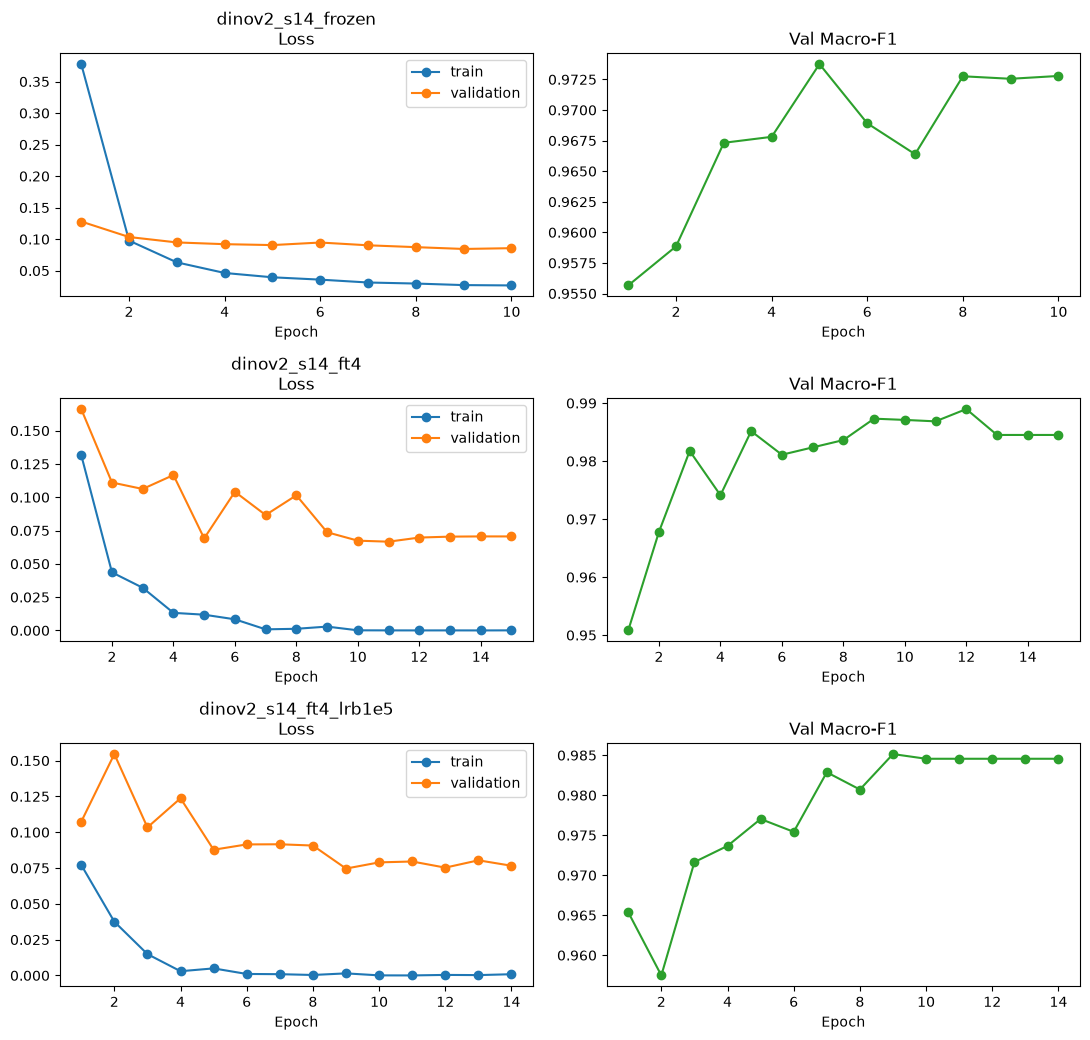

In [15]:
experiments = [(CFG_A, result_A), (CFG_B, result_B), (CFG_C, result_C)]
results = [r for _, r in experiments]

summary = pd.DataFrame([{
    "eksperimen": r["name"], "lr_backbone": cfg["lr_backbone"], "best_epoch": r["best_epoch"],
    "val_accuracy": r["val_acc"], "val_macro_f1": r["val_macro_f1"],
    "checkpoint": Path(r["best_ckpt"]).name} for cfg, r in experiments])
print(summary.round(4).to_string(index=False))

# perbandingan C terhadap B
selisih_f1 = result_C["val_macro_f1"] - result_B["val_macro_f1"]
selisih_gambar = round((result_C["val_acc"] - result_B["val_acc"]) * len(val_idx))
print(f"\nSelisih Macro-F1 C - B: {selisih_f1:+.4f} | selisih akurasi setara sekitar {selisih_gambar:+d} gambar")
if abs(selisih_gambar) <= 3:
    print("Selisih sangat kecil, belum tentu bermakna (validation hanya sekitar 551 gambar, satu seed).")

# kandidat terbaik berdasarkan Macro-F1 (jika sama, urutan A, B, C: yang lebih awal dipertahankan)
best_result = max(results, key=lambda r: r["val_macro_f1"])
h = best_result["history"][best_result["best_epoch"] - 1]
print(f"\nModel terbaik: {best_result['strategy']} (epoch {best_result['best_epoch']})")
print(f"Selisih train accuracy - val accuracy di epoch terbaik: {h['train_acc'] - h['val_acc']:+.4f}")

fig, axes = plt.subplots(len(results), 2, figsize=(11, 3.5 * len(results)))
for row, r in zip(axes, results):
    hist = pd.DataFrame(r["history"])
    row[0].plot(hist["epoch"], hist["train_loss"], marker="o", label="train")
    row[0].plot(hist["epoch"], hist["val_loss"], marker="o", label="validation")
    row[0].set_title(f"{r['name']}\nLoss")
    row[0].legend()
    row[1].plot(hist["epoch"], hist["val_macro_f1"], marker="o", color="tab:green")
    row[1].set_title("Val Macro-F1")
    for a in row:
        a.set_xlabel("Epoch")
plt.tight_layout()
plt.show()

## 11. Analisis validation

Melihat performa model terbaik per kelas, bukan hanya satu angka.

Bobot terbaik dimuat ke model baru (`pretrained=False`), lalu dievaluasi pada seluruh validation set.

**Catatan:**
- **F1 per kelas**: kelas dengan nilai terendah adalah titik terlemah model.
- **Confusion matrix**: baris adalah kelas aktual dan kolom adalah prediksi. Angka di luar diagonal menunjukkan pasangan kelas yang sering tertukar.
- **Contoh salah prediksi**: beberapa gambar yang salah ditebak, untuk memahami jenis kesalahannya. Kesalahan prediksi tidak otomatis berarti label gambar salah, dan label tidak diubah otomatis.

Accuracy: 0.9891 | Macro-F1: 0.9890

F1 per kelas:
botol_plastik    0.9953
gelas_plastik    0.9855
kertas_kardus    0.9865
saset_kemasan    0.9888
styrofoam        0.9888


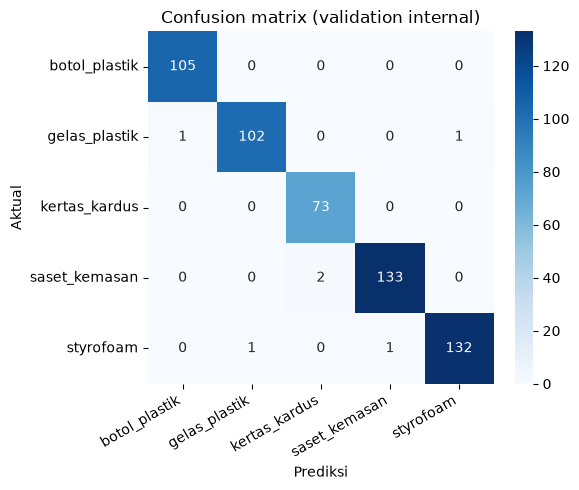

Salah prediksi: 6 dari 551


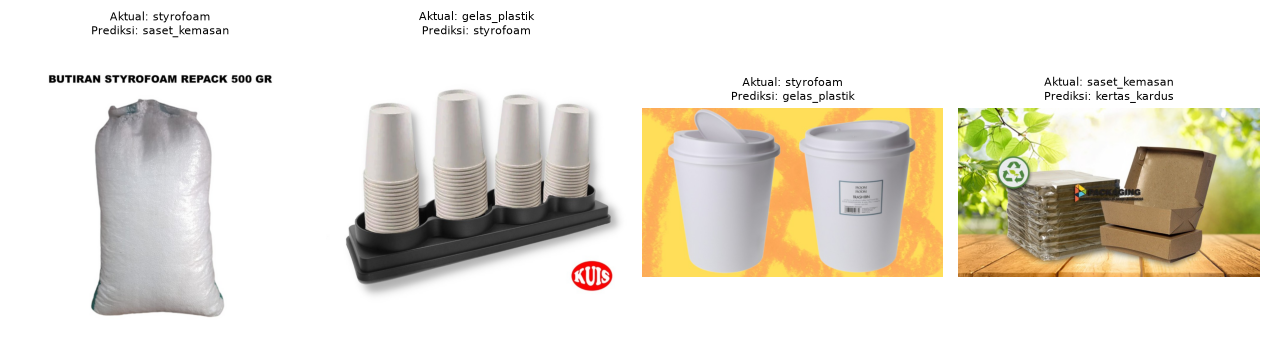

In [17]:
best_model = build_model(pretrained=False).to(device)
best_ckpt = torch.load(best_result["best_ckpt"], map_location="cpu", weights_only=False)
best_model.load_state_dict(best_ckpt["model_state_dict"])

val_loss, val_acc, val_f1, val_preds, val_labels = evaluate(best_model, val_loader)
print(f"Accuracy: {val_acc:.4f} | Macro-F1: {val_f1:.4f}\n")

f1_per_class = f1_score(val_labels, val_preds, average=None)
print("F1 per kelas:")
print(pd.Series(f1_per_class, index=CLASS_NAMES).round(4).to_string())

cm = confusion_matrix(val_labels, val_preds)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
plt.xlabel("Prediksi")
plt.ylabel("Aktual")
plt.title("Confusion matrix (validation internal)")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

# beberapa contoh salah prediksi
salah = np.where(val_preds != val_labels)[0]
print(f"Salah prediksi: {len(salah)} dari {len(val_labels)}")
n_show = min(4, len(salah))
if n_show:
    pilih = np.random.default_rng(SEED).choice(salah, size=n_show, replace=False)
    plt.figure(figsize=(3.2 * n_show, 3.4))
    for i, k in enumerate(pilih):
        a, p = int(val_labels[k]), int(val_preds[k])
        plt.subplot(1, n_show, i + 1)
        plt.imshow(Image.open(val_full.samples[val_idx[k]][0]).convert("RGB"))
        plt.axis("off")
        plt.title(f"Aktual: {CLASS_NAMES[a]}\nPrediksi: {CLASS_NAMES[p]}", fontsize=8)
    plt.tight_layout()
    plt.show()

## 12. Menyimpan `model.pth` ke `submission/`

**Tujuan.** Memastikan `submission/model.py` dan `submission/model.pth` siap diuji.

**Pembagian tugas dua file.**
- **`model.py`** dibuat dan diedit langsung sebagai file, bukan lewat notebook. Isinya `get_model()` (membangun arsitektur tanpa mengunduh bobot), `get_transform()` (sama dengan transformasi validation), dan konstanta model. Notebook hanya **membacanya**.
- **`model.pth`** berisi bobot hasil belajar. Ini satu-satunya file yang bisa ditulis dari notebook, lewat cell di bawah.

**Cara memakai cell di bawah.**
- `SIMPAN_PTH = False`: tidak ada yang ditulis. Pakai ini jika `model.pth` yang sekarang sudah benar.
- `SIMPAN_PTH = True`: bobot dari **checkpoint terbaik** model terpilih (bukan epoch terakhir) disimpan sebagai `state_dict` murni, menimpa `model.pth` lama. Kembalikan ke `False` setelah dijalankan.

In [23]:
# SIMPAN_PTH = False   # ubah True kalo ingin simpan model menjadi model utama 
SIMPAN_PTH = True 

if SIMPAN_PTH:
    ckpt_best = torch.load(best_result["best_ckpt"], map_location="cpu", weights_only=False)
    state = {k: v.detach().cpu().clone() for k, v in ckpt_best["model_state_dict"].items()}
    assert "model_state_dict" not in state
    save_atomic(state, MODEL_PTH_PATH)
    print(f"model.pth diperbarui dari {best_result['name']} | epoch {ckpt_best['epoch']} | Val Macro-F1 {ckpt_best['val_macro_f1']:.4f}")
else:
    print("model.pth tidak diubah.")
print(f"model.py : {MODEL_PY_PATH}")
print(f"model.pth: {MODEL_PTH_PATH} ({MODEL_PTH_PATH.stat().st_size / 1024**2:.1f} MB)")

model.pth diperbarui dari dinov2_s14_ft4 | epoch 12 | Val Macro-F1 0.9890
model.py : /home/sembiring/machine_learning/00_pr0j3ct/trash-image-classifier/submission/model.py
model.pth: /home/sembiring/machine_learning/00_pr0j3ct/trash-image-classifier/submission/model.pth (82.6 MB)


## 13. Pengujian submission

**Tujuan.** Membuktikan bahwa `model.py` dan `model.pth` bekerja mandiri dan cocok dengan model terbaik di notebook.

**Yang diuji di cell pertama.**
1. `model.py` dibaca ulang dari file, dan konstantanya cocok dengan notebook.
2. `get_model()` membangun model, lalu `model.pth` dimuat dengan `strict=True`.
3. Output model berbentuk `[batch, 5]`.
4. Transformasi menghasilkan tensor `[3, 224, 224]` yang identik dengan transformasi validation.
5. Logits model submission sama dengan model terbaik di notebook.

**Cara membaca hasilnya.**
- `Pemeriksaan lokal submission: BERHASIL` berarti `model.pth` yang ada sama dengan model terbaik. Tidak perlu apa-apa lagi.
- Gagal di bagian selisih logits berarti `model.pth` berasal dari model lain. Ubah `SIMPAN_PTH = True` di bagian 13, jalankan sekali, kembalikan ke `False`, lalu ulangi pengujian.

**Cell kedua** menjalankan `evaluate.py` milik dosen tanpa mengubah isinya. Sesuaikan `EVAL_CMD` jika argumen `evaluate.py` Anda berbeda.

**Cara membaca skor `evaluate.py`.** Karena `my_val/` overlap dengan `train/`, skor di sana hanya membuktikan bahwa pasangan `model.py` dan `model.pth` **kompatibel** dengan evaluator. Skor itu **bukan** ukuran kemampuan pada gambar baru. Ukuran yang lebih jujur adalah Macro-F1 validation internal di bagian 11 dan 12.

In [24]:
raw = torch.load(MODEL_PTH_PATH, map_location="cpu")
print(type(raw).__name__, "| jumlah kunci:", len(raw))
print(list(raw.keys())[:5])

dict | jumlah kunci: 176
['cls_token', 'pos_embed', 'patch_embed.proj.weight', 'patch_embed.proj.bias', 'blocks.0.norm1.weight']


In [25]:
sub = load_submission_module()   # dibaca ulang dari file, jadi edit terbaru ikut terbaca

assert sub.MODEL_NAME == MODEL_NAME and sub.NUM_CLASSES == NUM_CLASSES and sub.IMAGE_SIZE == IMAGE_SIZE
assert tuple(sub.IMAGENET_MEAN) == IMAGENET_MEAN and tuple(sub.IMAGENET_STD) == IMAGENET_STD
assert list(sub.CLASS_NAMES) == CLASS_NAMES, "Urutan kelas model.py berbeda"

sub_model = sub.get_model()
sub_model.load_state_dict(torch.load(MODEL_PTH_PATH, map_location="cpu"), strict=True)
sub_model = sub_model.to(device).eval()
best_model.eval()

with torch.inference_mode():
    out = sub_model(torch.randn(2, 3, IMAGE_SIZE, IMAGE_SIZE, device=device))
print("Output model    :", tuple(out.shape))
assert out.shape == (2, NUM_CLASSES)

sub_tf = sub.get_transform()
path0 = val_full.samples[val_idx[0]][0]
t_sub = sub_tf(Image.open(path0).convert("RGB"))
print("Output transform:", tuple(t_sub.shape))
assert t_sub.shape == (3, IMAGE_SIZE, IMAGE_SIZE)
assert torch.allclose(t_sub, val_tfms(Image.open(path0).convert("RGB"))), "Transform berbeda dari validation notebook"

batch = torch.stack([sub_tf(Image.open(val_full.samples[i][0]).convert("RGB")) for i in val_idx[:64]]).to(device)
with torch.inference_mode():
    selisih = (sub_model(batch) - best_model(batch)).abs().max().item()
print(f"Selisih logits maksimum (submission vs training): {selisih:.2e}")
assert selisih < 1e-3

print("Pemeriksaan lokal submission: BERHASIL")

Output model    : (2, 5)
Output transform: (3, 224, 224)
Selisih logits maksimum (submission vs training): 0.00e+00
Pemeriksaan lokal submission: BERHASIL


In [26]:
EVAL_CMD = [sys.executable, "evaluate.py", "--submission", "./submission", "--data", "./my_val"]

if not (PROJECT_DIR / "evaluate.py").exists():
    print("evaluate.py tidak ditemukan, pengujian resmi belum dilakukan.")
else:
    proc = subprocess.run(EVAL_CMD, cwd=PROJECT_DIR, capture_output=True, text=True)
    print("Status evaluate.py:", "BERHASIL" if proc.returncode == 0 else f"GAGAL (returncode {proc.returncode})")
    print(proc.stdout[-2000:])
    if proc.returncode != 0:
        print("--- pesan error ---")
        print(proc.stderr[-3000:])
    if my_val_overlap:
        print(f"CATATAN: {my_val_overlap} dari {my_val_total} gambar my_val identik dengan train, "
              "jadi skor di atas hanya uji kompatibilitas, bukan evaluasi independen.")

Status evaluate.py: BERHASIL
device=cuda  gambar=2753

Macro-F1 : 0.9978
Akurasi  : 0.9978
  F1 botol_plastik   0.9990
  F1 gelas_plastik   0.9971
  F1 kertas_kardus   0.9973
  F1 saset_kemasan   0.9978
  F1 styrofoam       0.9978
Confusion matrix (baris = label asli, kolom = prediksi):
  botol_plastik   [523, 0, 0, 0, 0]
  gelas_plastik   [1, 519, 0, 0, 1]
  kertas_kardus   [0, 0, 365, 0, 0]
  saset_kemasan   [0, 0, 2, 671, 0]
  styrofoam       [0, 1, 0, 1, 669]

CATATAN: 2753 dari 2753 gambar my_val identik dengan train, jadi skor di atas hanya uji kompatibilitas, bukan evaluasi independen.


## 15. Ringkasan

In [27]:
print("=== RINGKASAN ===")
print(f"Total gambar train : {len(all_files)} | train {len(train_idx)} / val {len(val_idx)} ({split_source})")
print(f"Model / input      : {MODEL_NAME} | {IMAGE_SIZE}x{IMAGE_SIZE}")
print(summary.round(4).to_string(index=False))
print(f"\nModel terbaik      : {best_result['strategy']} (epoch {best_result['best_epoch']})")
print(f"Val accuracy       : {val_acc:.4f}")
print(f"Val Macro-F1       : {val_f1:.4f}")
print(f"Submission         : {MODEL_PY_PATH.name} + {MODEL_PTH_PATH.name} di {SUBMISSION_DIR}")
print("\nCatatan: skor di atas dari validation internal, bukan skor hidden validation dosen.")

=== RINGKASAN ===
Total gambar train : 2753 | train 2202 / val 551 (dibuat di memori (stratified, seed 42))
Model / input      : vit_small_patch14_dinov2.lvd142m | 224x224
           eksperimen  lr_backbone  best_epoch  val_accuracy  val_macro_f1                     checkpoint
    dinov2_s14_frozen          NaN           5        0.9746        0.9738     dinov2_s14_frozen_best.pth
       dinov2_s14_ft4          0.0          12        0.9891        0.9890        dinov2_s14_ft4_best.pth
dinov2_s14_ft4_lrb1e5          0.0           9        0.9855        0.9851 dinov2_s14_ft4_lrb1e5_best.pth

Model terbaik      : Partial fine-tuning (4 blok terakhir + head) (epoch 12)
Val accuracy       : 0.9891
Val Macro-F1       : 0.9890
Submission         : model.py + model.pth di /home/sembiring/machine_learning/00_pr0j3ct/trash-image-classifier/submission

Catatan: skor di atas dari validation internal, bukan skor hidden validation dosen.
